# Tugas Praktikum JS04 - Dataset PBL
## Clustering K-Means dan DBSCAN pada Berita Hoaks


### 1. Load dataset PBL


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
df.head()


Dimensi data: (1498, 2)


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


### 2. Ekstraksi fitur TF-IDF


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks_bersih']).toarray()
y = df['label'].values
print('Dimensi matriks fitur:', X.shape)


Dimensi matriks fitur: (1498, 1000)


### 3. Clustering K-Means (K=2)


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X)

sil_kmeans = silhouette_score(X, labels_kmeans)
dbi_kmeans = davies_bouldin_score(X, labels_kmeans)

print(f'Silhouette Score K-Means: {sil_kmeans:.4f}')
print(f'Davies-Bouldin Index K-Means: {dbi_kmeans:.4f}')
print('Distribusi cluster K-Means:')
print(pd.Series(labels_kmeans).value_counts())


C:\Users\azure\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


Silhouette Score K-Means: 0.0164
Davies-Bouldin Index K-Means: 3.1935
Distribusi cluster K-Means:
1    1398
0     100
Name: count, dtype: int64


### 4. Clustering DBSCAN (Cosine Distance)


In [4]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.7, min_samples=5, metric='cosine')
labels_dbscan = dbscan.fit_predict(X)

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = (labels_dbscan == -1).sum()

print(f'Jumlah cluster DBSCAN: {n_clusters_db}')
print(f'Jumlah data noise: {n_noise_db}')
if n_clusters_db > 1:
    mask = labels_dbscan != -1
    if len(set(labels_dbscan[mask])) > 1:
        sil_db = silhouette_score(X[mask], labels_dbscan[mask])
        print(f'Silhouette Score DBSCAN (tanpa noise): {sil_db:.4f}')


Jumlah cluster DBSCAN: 6
Jumlah data noise: 171
Silhouette Score DBSCAN (tanpa noise): -0.0085


### 5. Visualisasi 2D hasil clustering dengan TruncatedSVD


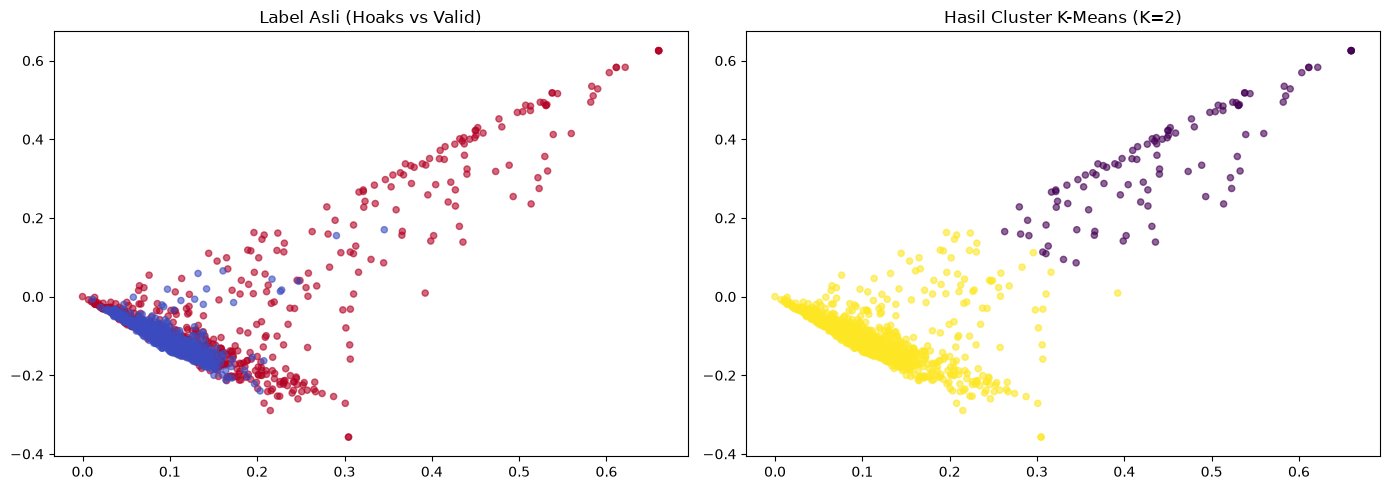

In [5]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='coolwarm', alpha=0.6, s=20)
axes[0].set_title('Label Asli (Hoaks vs Valid)')

axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=labels_kmeans, cmap='viridis', alpha=0.6, s=20)
axes[1].set_title('Hasil Cluster K-Means (K=2)')

plt.tight_layout()
plt.show()
